In [33]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl   
import stmpy

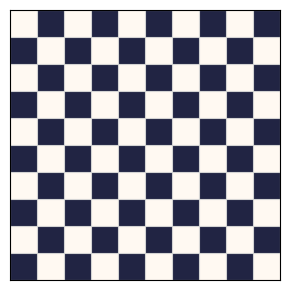

In [ ]:
img = np.full((10, 10), 255, dtype=np.uint8)

i, j = np.indices((10, 10))
img = np.where((i + j) % 2 == 0, 255, 30).astype(np.uint8)

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(img, cmap=stmpy.cm.jackyPSD, vmin=0, vmax=255)

# Grid aligned to pixel boundaries
ax.set_xticks(np.arange(-0.5, 10, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
ax.grid(which='minor', color='lightgray', linewidth=0.8)
ax.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)

plt.tight_layout()
plt.savefig("vertical_line.pdf", dpi=300)
plt.show()

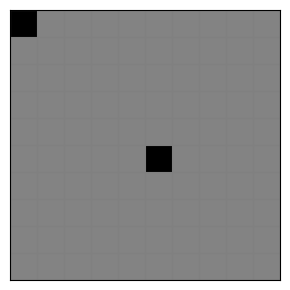

In [ ]:
F = np.fft.fft2(img)
F_shifted = np.fft.fftshift(F)
magnitude = np.abs(F_shifted)

c, s = magnitude.mean(), magnitude.std()

fig, ax = plt.subplots(figsize=(3, 3))
im = ax.imshow(magnitude, stmpy.cm.gray_r ,clim=(c - 5*s, c + 5*s))
ax.set_xticks(np.arange(-0.5, 10, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
ax.grid(which='minor', color='gray', linewidth=0.8)
ax.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)
plt.tight_layout()
plt.savefig("fft_vertical_line.pdf", dpi=300)
plt.show()

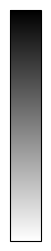

In [36]:
fig_cb, ax_cb = plt.subplots(figsize=(0.4, 3))
norm = mpl.colors.Normalize(vmin=magnitude.min(), vmax=magnitude.max())
cb = fig_cb.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=stmpy.cm.gray_r), cax=ax_cb)
cb.set_ticks([])
fig_cb.savefig("colorbar.pdf", bbox_inches='tight')
plt.show()

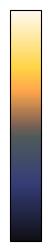

In [38]:
fig_cb_real, ax_cb_real = plt.subplots(figsize=(0.4, 3))
norm_real = mpl.colors.Normalize(vmin=0, vmax=255)
cb_real = fig_cb_real.colorbar(mpl.cm.ScalarMappable(norm=norm_real, cmap=stmpy.cm.jackyPSD), cax=ax_cb_real)
cb_real.set_ticks([])
fig_cb_real.savefig("colorbar_real.pdf", bbox_inches='tight')
plt.show()